# 1.import libs and load data from excel (local path)
# 2.define variables of interest
# 3-6. descriptive stats
# 7.save 
# 8.left vs. right comparison
# 9.pooling left and right
# 10.comparison of controls
# 11.pooling ctrl
# 12.visualization
# 13.inferrential stats (assumption of EV, ANOVA, ANOVA with correction, or Kruskal-Wallis-non parametric)
# 14.pairwise multiple comparisons with corrections
# 15.Dunnett's significance plot


In [29]:
import pandas as pd                # pandas: tables ("DataFrames") and statistics
import matplotlib.pyplot as plt    # matplotlib: plots

# Path to your Excel file. Change this if you move the file.
DATA_FILE = "/Users/shawnlam/Everything GRAD/Handscore thyroids.xlsx"

# read_excel loads the sheet into a DataFrame (a table, like a spreadsheet).
df = pd.read_excel(DATA_FILE)

# .head() shows the first 5 rows so you can check that it loaded correctly.
df.head()

,Subject,Sex,Drug,Side,Area
0,SP103,M,MC,L,0.122
1,SP103,M,MC,R,0.111
2,SP93,M,MC,L,0.075
3,SP93,M,MC,R,0.087
4,LB26,F,MC,L,0.146


In [30]:
# Name the columns by role, so the rest of the code never repeats the strings.
id_col = "Subject"
outcome = "Area"                          # the number we want to describe
group_cols = ["Sex", "Drug", "Side"]      # the labels we group by

# The order we want treatment groups displayed in (edit if you prefer another).
drug_order = ["Saline", "MC", "MMI-L", "MMI-H", "PTU-L", "PTU-H"]

# Convert text columns to "category" type, with the Drug order applied.
df["Sex"] = df["Sex"].astype("category")
df["Side"] = df["Side"].astype("category")
df["Drug"] = pd.Categorical(df["Drug"], categories=drug_order, ordered=True)

# .dtypes lists each column's data type to confirm the conversion worked.
df.dtypes

Subject         str
Sex        category
Drug       category
Side       category
Area        float64
dtype: object

In [31]:
# Number of unique animals and number of measurements (rows).
print("Animals:", df[id_col].nunique())
print("Measurements:", len(df))

# Animals that do not have exactly 2 measurements (a missing side).
rows_per_animal = df.groupby(id_col).size()
print("\nAnimals without both sides:")
print(rows_per_animal[rows_per_animal != 2])

# Number of animals in each Drug x Sex group.
# observed=True hides empty category combinations.
animals_per_group = (
    df.groupby(["Drug", "Sex"], observed=True)[id_col]
      .nunique()
      .unstack("Sex")        # puts Sex across the columns
)
animals_per_group

Animals: 24
Measurements: 44

Animals without both sides:
Subject
LB73      1
SSP118    1
WH194     1
WH94      1
dtype: int64


Sex,F,M
Drug,,
Saline,3,2
MC,2,2
MMI-L,1,2
MMI-H,2,2
PTU-L,2,2
PTU-H,2,2


In [32]:
df[outcome].describe()
# A reusable list of the statistics we want.
stats = ["count", "mean", "std", "sem", "median", "min", "max"]

def summarize(by):
    """Return descriptive statistics of Area for the column(s) in `by`."""
    return (
        df.groupby(by, observed=True)[outcome]
          .agg(stats)
          .round(4)  # round to 4 decimal places for readability
    )

print("By Drug")
display(summarize("Drug"))

print("By Sex")
display(summarize("Sex"))

print("By Side")
display(summarize("Side"))

print("By Drug and Sex")
display(summarize(["Drug", "Sex"]))

By Drug


,count,mean,std,sem,median,min,max
Drug,,,,,,,
Saline,7,0.1031,0.0116,0.0044,0.1010,0.090,0.118
MC,8,0.1066,0.0238,0.0084,0.1040,0.075,0.146
MMI-L,6,0.1342,0.0098,0.0040,0.1325,0.123,0.150
MMI-H,8,0.1474,0.0480,0.0170,0.1340,0.099,0.228
PTU-L,8,0.1195,0.0238,0.0084,0.1110,0.093,0.163
PTU-H,7,0.1410,0.0218,0.0082,0.1440,0.118,0.169


By Sex


,count,mean,std,sem,median,min,max
Sex,,,,,,,
F,21,0.1321,0.0362,0.0079,0.118,0.089,0.228
M,23,0.1186,0.0238,0.0050,0.119,0.075,0.166


By Side


,count,mean,std,sem,median,min,max
Side,,,,,,,
L,23,0.1238,0.0297,0.0062,0.119,0.075,0.210
R,21,0.1264,0.0326,0.0071,0.119,0.087,0.228


By Drug and Sex


count    mean     std     sem  median    min    max
Drug   Sex                                                     
Saline F        4  0.1098  0.0104  0.0052  0.1130  0.095  0.118
       M        3  0.0943  0.0059  0.0034  0.0920  0.090  0.101
MC     F        4  0.1145  0.0263  0.0132  0.1115  0.089  0.146
       M        4  0.0988  0.0215  0.0108  0.0990  0.075  0.122
MMI-L  F        2  0.1310  0.0113  0.0080  0.1310  0.123  0.139
       M        4  0.1358  0.0104  0.0052  0.1325  0.128  0.150
MMI-H  F        4  0.1628  0.0657  0.0328  0.1620  0.099  0.228
       M        4  0.1320  0.0206  0.0103  0.1340  0.105  0.155
PTU-L  F        4  0.1332  0.0264  0.0132  0.1295  0.111  0.163
       M        4  0.1058  0.0108  0.0054  0.1055  0.093  0.119
PTU-H  F        3  0.1437  0.0255  0.0147  0.1440  0.118  0.169
       M        4  0.1390  0.0225  0.0112  0.1355  0.119  0.166

In [33]:
# One row per animal: average Area across its available sides.
# Sex and Drug are the same for every row of an animal, so "first" keeps them.
animal_df = (
    df.groupby(id_col, observed=True)
      .agg(Sex=("Sex", "first"),
           Drug=("Drug", "first"),
           Area=(outcome, "mean"),
           n_sides=(outcome, "size"))
      .reset_index()
)

animal_summary = (
    animal_df.groupby("Drug", observed=True)["Area"]
             .agg(["count", "mean", "std", "sem", "median", "min", "max"])
             .round(4)
)
animal_summary

,count,mean,std,sem,median,min,max
Drug,,,,,,,
Saline,5,0.1019,0.0110,0.0049,0.0955,0.0920,0.1170
MC,4,0.1066,0.0180,0.0090,0.1120,0.0810,0.1215
MMI-L,3,0.1342,0.0043,0.0025,0.1325,0.1310,0.1390
MMI-H,4,0.1474,0.0501,0.0251,0.1320,0.1065,0.2190
PTU-L,4,0.1195,0.0245,0.0123,0.1110,0.1005,0.1555
PTU-H,4,0.1381,0.0218,0.0109,0.1385,0.1180,0.1575


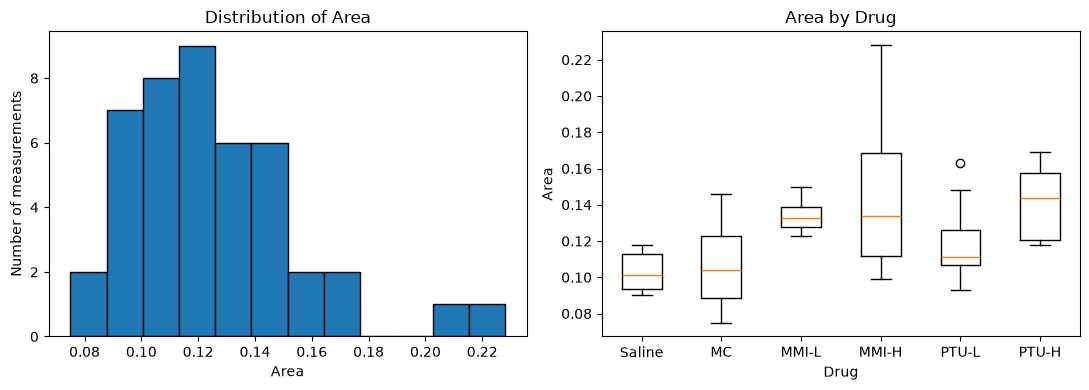

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: histogram shows the overall shape of Area (is it skewed? any outliers?).
axes[0].hist(df[outcome], bins=12, edgecolor="black")
axes[0].set_xlabel("Area")
axes[0].set_ylabel("Number of measurements")
axes[0].set_title("Distribution of Area")

# Right: boxplot per Drug group (line = median, box = middle 50% of data).
groups = [g[outcome].values for _, g in df.groupby("Drug", observed=True)]
labels = [name for name, _ in df.groupby("Drug", observed=True)]
axes[1].boxplot(groups, tick_labels=labels)
axes[1].set_xlabel("Drug")
axes[1].set_ylabel("Area")
axes[1].set_title("Area by Drug")

plt.tight_layout()
plt.show()

In [35]:
from scipy import stats    # scipy.stats: statistical tests
import numpy as np

alpha = 0.05               # significance threshold: p < alpha means "significant"

# Reshape so each animal is one row with a column for L and a column for R.
# dropna() removes animals that only have one side measured (they cannot be paired).
wide = df.pivot(index="Subject", columns="Side", values="Area").dropna()
print("Animals with both sides:", len(wide))

# The difference between sides for each animal.
diff = wide["L"] - wide["R"]
print("Mean difference (L - R):", round(diff.mean(), 5))

# Shapiro-Wilk: p > 0.05 means the differences look normal enough for a t-test.
shapiro_p = stats.shapiro(diff).pvalue
print("Shapiro-Wilk p (normality of differences):", round(shapiro_p, 3))

# Paired t-test: are L and R means different?
t_stat, p_paired = stats.ttest_rel(wide["L"], wide["R"])
print("Paired t-test: t =", round(t_stat, 3), ", p =", round(p_paired, 3))

# Wilcoxon signed-rank test: the non-parametric alternative.
p_wilcoxon = stats.wilcoxon(wide["L"], wide["R"]).pvalue
print("Wilcoxon p:", round(p_wilcoxon, 3))

# Correlation: how similar are the two sides within an animal?
print("L-R correlation (r):", round(wide["L"].corr(wide["R"]), 3))

# Decision: pool only if the test finds no significant difference.
pool_sides = p_paired > alpha
print("\nPool left and right?", "YES" if pool_sides else "NO")

Animals with both sides: 20
Mean difference (L - R): -5e-05
Shapiro-Wilk p (normality of differences): 0.569
Paired t-test: t = -0.01 , p = 0.992
Wilcoxon p: 0.841
L-R correlation (r): 0.778

Pool left and right? YES


In [36]:
if pool_sides:
    # Average Area across the sides of each animal.
    # Sex and Drug are the same for all rows of an animal, so "first" keeps them.
    pooled = (
        df.groupby("Subject", observed=True)
          .agg(Sex=("Sex", "first"),
               Drug=("Drug", "first"),
               Area_pooled=("Area", "mean"))
          .reset_index()
    )
    print("Pooled data: one row per animal,", len(pooled), "animals")
    display(pooled.head())
else:
    print("L and R differ, so they were NOT pooled. Analyse the sides separately.")

Pooled data: one row per animal, 24 animals


,Subject,Sex,Drug,Area_pooled
0,L57,M,PTU-L,0.1110
1,L86,M,PTU-L,0.1005
2,LB109,F,PTU-L,0.1555
3,LB141,M,MMI-L,0.1390
4,LB165,M,MMI-H,0.1435


In [37]:
if not pool_sides:
    print("Skipped: sides were not pooled.")
else:
    # Pull out the pooled Area values of each group as separate lists.
    saline = pooled.loc[pooled["Drug"] == "Saline", "Area_pooled"]
    mc     = pooled.loc[pooled["Drug"] == "MC",     "Area_pooled"]

    print("Saline: n =", len(saline), ", mean =", round(saline.mean(), 4), ", SD =", round(saline.std(), 4))
    print("MC:     n =", len(mc),     ", mean =", round(mc.mean(), 4),     ", SD =", round(mc.std(), 4))

    # Assumption checks (p > 0.05 = assumption looks fine).
    print("\nShapiro p (Saline):", round(stats.shapiro(saline).pvalue, 3))
    print("Shapiro p (MC):    ", round(stats.shapiro(mc).pvalue, 3))
    print("Levene p (equal variance):", round(stats.levene(saline, mc).pvalue, 3))

    # Welch's t-test (equal_var=False).
    t_stat, p_welch = stats.ttest_ind(saline, mc, equal_var=False)
    print("\nWelch t-test: t =", round(t_stat, 3), ", p =", round(p_welch, 3))

    # Mann-Whitney U test.
    p_mw = stats.mannwhitneyu(saline, mc).pvalue
    print("Mann-Whitney p:", round(p_mw, 3))

    # Effect size (Cohen's d): difference in means in units of pooled SD.
    # Useful because with tiny groups a non-significant p can hide a real effect.
    sd_pooled = np.sqrt(((len(saline)-1)*saline.var() + (len(mc)-1)*mc.var()) / (len(saline)+len(mc)-2))
    print("Cohen's d:", round((mc.mean() - saline.mean()) / sd_pooled, 2))

    pool_controls = p_welch > alpha
    print("\nPool Saline and MC into one control group?", "YES" if pool_controls else "NO")

Saline: n = 5 , mean = 0.1019 , SD = 0.011
MC:     n = 4 , mean = 0.1066 , SD = 0.018

Shapiro p (Saline): 0.204
Shapiro p (MC):     0.344
Levene p (equal variance): 0.571

Welch t-test: t = -0.46 , p = 0.666
Mann-Whitney p: 0.73
Cohen's d: 0.33

Pool Saline and MC into one control group? YES


In [38]:
if pool_sides and pool_controls:
    # Make a new column "Group": Saline and MC become "Control"; other drugs keep their name.
    pooled["Group"] = pooled["Drug"].astype(str).replace({"Saline": "Control", "MC": "Control"})

    # Put the groups in a sensible order for tables and plots.
    group_order = ["Control", "MMI-L", "MMI-H", "PTU-L", "PTU-H"]
    pooled["Group"] = pd.Categorical(pooled["Group"], categories=group_order, ordered=True)

    # Descriptive statistics of the pooled variable for each group.
    display(
        pooled.groupby("Group", observed=True)["Area_pooled"]
              .agg(["count", "mean", "std", "sem", "median", "min", "max"])
              .round(4)
    )
else:
    print("Saline and MC were not pooled (or sides were not pooled).")

,count,mean,std,sem,median,min,max
Group,,,,,,,
Control,9,0.1040,0.0137,0.0046,0.1075,0.0810,0.1215
MMI-L,3,0.1342,0.0043,0.0025,0.1325,0.1310,0.1390
MMI-H,4,0.1474,0.0501,0.0251,0.1320,0.1065,0.2190
PTU-L,4,0.1195,0.0245,0.0123,0.1110,0.1005,0.1555
PTU-H,4,0.1381,0.0218,0.0109,0.1385,0.1180,0.1575


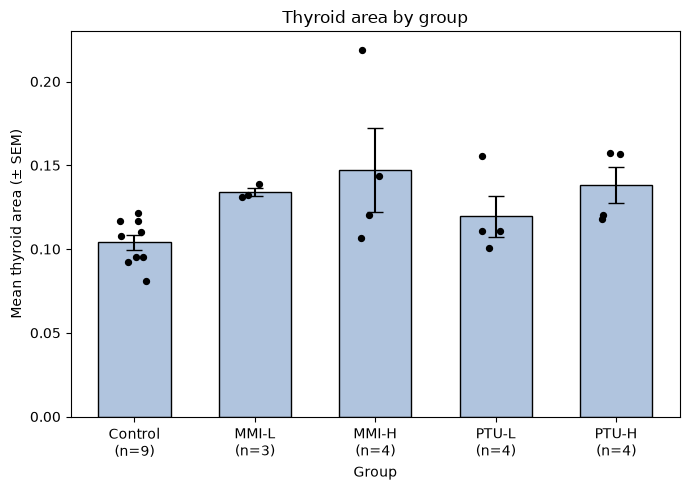

,mean,sem,n
Group,,,
Control,0.1040,0.0046,9
MMI-L,0.1342,0.0025,3
MMI-H,0.1474,0.0251,4
PTU-L,0.1195,0.0123,4
PTU-H,0.1381,0.0109,4


In [39]:
# Mean, SEM and n for each group (pooled Area, one value per animal).
summary = (
    pooled.groupby("Group", observed=True)["Area_pooled"]
          .agg(mean="mean", sem="sem", n="count")
)

fig, ax = plt.subplots(figsize=(7, 5))

# Positions of the bars on the x-axis: 0, 1, 2, ...
x = np.arange(len(summary))

# Draw the bars at the group means.
# yerr adds the SEM error bars; capsize sets the width of the little caps.
ax.bar(x, summary["mean"], yerr=summary["sem"],
       capsize=6, color="lightsteelblue", edgecolor="black", width=0.6)

# Overlay each animal as a dot on its group's bar.
for i, group in enumerate(summary.index):
    values = pooled.loc[pooled["Group"] == group, "Area_pooled"]
    # Small random horizontal shift so overlapping dots stay visible.
    jitter = np.random.default_rng(0).uniform(-0.12, 0.12, size=len(values))
    ax.scatter(i + jitter, values, color="black", s=18, zorder=3)

# Label each bar with its group name and number of animals, e.g. "Control\n(n=9)".
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(summary.index, summary["n"])])

ax.set_ylabel("Mean thyroid area (± SEM)")   # add units here if you know them
ax.set_xlabel("Group")
ax.set_title("Thyroid area by group")

plt.tight_layout()
plt.savefig("area_by_group.png", dpi=300)   # saves a high-resolution image next to the notebook
plt.show()

# Show the numbers behind the plot.
summary.round(4)

In [40]:
from statsmodels.stats.oneway import anova_oneway   # Welch's ANOVA
from statsmodels.stats.multitest import multipletests

# Fixed group order, with Control first.
order = ["Control", "MMI-L", "MMI-H", "PTU-L", "PTU-H"]

# A dictionary: group name -> array of that group's animal-level Area values.
groups = {g: pooled.loc[pooled["Group"] == g, "Area_pooled"].to_numpy() for g in order}
print({g: len(v) for g, v in groups.items()})   # sample size per group

# Levene's test: p > 0.05 means the spread of the groups is similar enough.
levene_p = stats.levene(*groups.values()).pvalue
print("\nLevene p (equal variance):", round(levene_p, 3))

# One-way ANOVA.
f_stat, p_anova = stats.f_oneway(*groups.values())
print("One-way ANOVA:   F =", round(f_stat, 3), ", p =", round(p_anova, 4))

# Welch's ANOVA (use_var="unequal" means variances are allowed to differ).
welch = anova_oneway(list(groups.values()), use_var="unequal", welch_correction=True)
print("Welch's ANOVA:   F =", round(welch.statistic, 3), ", p =", round(welch.pvalue, 4))

# Kruskal-Wallis (rank-based, no normality assumption).
h_stat, p_kw = stats.kruskal(*groups.values())
print("Kruskal-Wallis:  H =", round(h_stat, 3), ", p =", round(p_kw, 4))

{'Control': 9, 'MMI-L': 3, 'MMI-H': 4, 'PTU-L': 4, 'PTU-H': 4}

Levene p (equal variance): 0.189
One-way ANOVA:   F = 2.686 , p = 0.0627
Welch's ANOVA:   F = 7.055 , p = 0.0115
Kruskal-Wallis:  H = 10.754 , p = 0.0295


In [41]:
control = groups["Control"]
treated = [g for g in order if g != "Control"]

# Dunnett's test: one call compares all treated groups with the control.
dunnett = stats.dunnett(*[groups[g] for g in treated], control=control)

# 95% confidence interval of each difference (treated - Control).
ci = dunnett.confidence_interval()

# Mann-Whitney U for each treated group vs Control, then Holm correction for 4 tests.
raw_p = [stats.mannwhitneyu(groups[g], control).pvalue for g in treated]
holm_p = multipletests(raw_p, method="holm")[1]

# Put everything in one table.
posthoc = pd.DataFrame({
    "n": [len(groups[g]) for g in treated],
    "mean": [groups[g].mean() for g in treated],
    "diff_vs_Control": [groups[g].mean() - control.mean() for g in treated],
    "CI_low": ci.low,
    "CI_high": ci.high,
    "Dunnett_p": dunnett.pvalue,
    "MannWhitney_Holm_p": holm_p,
}, index=treated).round(4)

# Add a column that flags significance at alpha (here 0.05).
posthoc["Dunnett_sig"] = np.where(posthoc["Dunnett_p"] < alpha, "*", "ns")
posthoc

,n,mean,diff_vs_Control,CI_low,CI_high,Dunnett_p,MannWhitney_Holm_p,Dunnett_sig
MMI-L,3,0.1342,0.0302,-0.0158,0.0762,0.2877,0.0364,ns
MMI-H,4,0.1474,0.0434,0.0019,0.0848,0.0385,0.1510,*
PTU-L,4,0.1195,0.0155,-0.0259,0.0569,0.7511,0.3301,ns
PTU-H,4,0.1381,0.0341,-0.0073,0.0756,0.1298,0.0364,ns


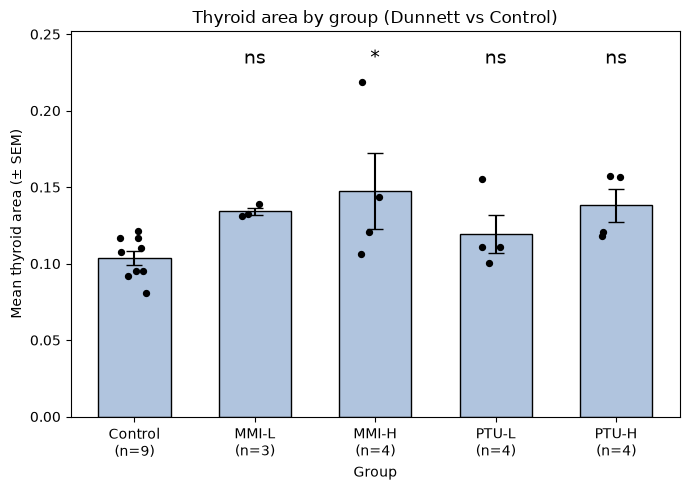

In [42]:
def stars(p):
    """Convert a p-value into the usual star label."""
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

# Mean, SEM and n for each group, in plotting order.
summary = (
    pooled.groupby("Group", observed=True)["Area_pooled"]
          .agg(mean="mean", sem="sem", n="count")
)

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(summary))

# Bars with SEM error bars.
ax.bar(x, summary["mean"], yerr=summary["sem"],
       capsize=6, color="lightsteelblue", edgecolor="black", width=0.6)

# Individual animals as dots.
for i, group in enumerate(summary.index):
    values = pooled.loc[pooled["Group"] == group, "Area_pooled"]
    jitter = np.random.default_rng(0).uniform(-0.12, 0.12, size=len(values))
    ax.scatter(i + jitter, values, color="black", s=18, zorder=3)

# Put a star label above each treated group (Control is the reference, so it gets none).
top = pooled["Area_pooled"].max()                  # highest dot, so labels sit above everything
for i, group in enumerate(summary.index):
    if group == "Control":
        continue
    label = stars(posthoc.loc[group, "Dunnett_p"])   # p-value from section 15
    ax.text(i, top * 1.04, label, ha="center", va="bottom", fontsize=14)

ax.set_ylim(0, top * 1.15)                         # leave room for the labels
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(summary.index, summary["n"])])
ax.set_ylabel("Mean thyroid area (± SEM)")
ax.set_xlabel("Group")
ax.set_title("Thyroid area by group (Dunnett vs Control)")

plt.tight_layout()
plt.savefig("area_by_group_stars.png", dpi=300)
plt.show()